| **Indicador**                                 | **Justificativa**                                                                                                                                           |
| --------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------- |
| IVS (Índice de Vulnerabilidade Social)        | É provavelmente o indicador mais relevante. Integra dimensões de infraestrutura urbana, capital humano e renda/trabalho.                                    |
| Taxa de pobreza                               | Captura privação material diretamente. Frequentemente associada a maior vulnerabilidade à exploração e tráfico.                                             |
| Índice Gini                                   | Mede desigualdade e não pobreza. Municípios ou estados ricos podem apresentar alto Gini. Pode acrescentar informação relevante sobre concentração de renda. |
| Taxa de desemprego                            | Representa fragilidade do mercado de trabalho local.                                                                                                        |
| Taxa de analfabetismo                         | Proxy importante de exclusão educacional e acesso à informação.                                                                                             |
| Razão de dependência                          | Reflete pressão econômica sobre a população economicamente ativa e perfil etário do território.                                                             |
| Bolsa Família (número absoluto de benefícios) | O número bruto é pouco informativo. Municípios grandes terão mais benefícios apenas por terem mais habitantes.                                              |

Abordagem exploratória e posterior identificação de perfis territoriais de vulnerabilidade associados ao tráfico de pessoas, o conjunto mais informativo e menos redundante provavelmente seria:

`IVS + Taxa de pobreza + Gini + Taxa de desemprego + Taxa de analfabetismo + Razão de dependência + Bolsa Família per capita`

e utilizaria IDHM apenas como variável de validação/convergência, pois ele tende a capturar informações já parcialmente presentes nas demais variáveis.


In [145]:
import pandas as pd
import numpy as np
from pathlib import Path

# ==========================================================
# 1. BASE PRINCIPAL
# ==========================================================

pasta_indicadores = r"../data/indicadores"

municipios = pd.read_csv(
    r"../data/municipios.csv", sep=";"
)

# municipios["municipio_id"] = municipios["municipio-id"].str.zfill(7)
# municipios["municipio_nome"] = municipios["municipio-nome"]
# municipios["uf_id"] = municipios["UF-id"]
# municipios["uf_sigla"] = municipios["UF-sigla"]
# municipios["estado"] = municipios["UF-nome"]
# municipios["regiao"] = municipios["regiao-nome"]

# df_clean = municipios[["municipio_id", "municipio_nome", "uf_id", "uf_sigla", "estado", "regiao"]].copy()

df_clean = municipios.copy()

df_clean["municipio_id"] = df_clean["municipio_id"].astype(str)

df_clean.to_csv(r"../data/municipios.csv", sep=";", index=False)

print(municipios.shape)
df_clean.head()

(5571, 6)


,municipio_id,municipio_nome,uf_id,uf_sigla,estado,regiao
0,1100015,Alta Floresta D'Oeste,11,RO,Rondônia,Norte
1,1100023,Ariquemes,11,RO,Rondônia,Norte
2,1100031,Cabixi,11,RO,Rondônia,Norte
3,1100049,Cacoal,11,RO,Rondônia,Norte
4,1100056,Cerejeiras,11,RO,Rondônia,Norte


2.  FUNÇÕES AUXILIARES


In [146]:
ANOS_INTERESSE = ["2021", "2022", "2023", "2024", "2025"]

def detectar_colunas_ano(df):
    """
    Localiza colunas com anos entre 2021-2025.
    """
    cols = []

    for c in df.columns:
        c_str = str(c)

        for ano in ANOS_INTERESSE:
            if ano in c_str:
                cols.append(c)
                break

    return cols


def renomear_colunas_anos(df, prefixo):
    """
    Ex:
    2021 -> renda_media_2021
    """
    mapa = {}

    for c in df.columns:
        for ano in ANOS_INTERESSE:
            if ano in str(c):
                mapa[c] = f"{prefixo}_{ano}"

    return df.rename(columns=mapa)


def preparar_indicador_municipal(
        arquivo,
        nome_indicador,
        coluna_chave="Código"
    ):
    """
    Indicadores vinculados ao município
    """

    df = pd.read_csv(arquivo, skiprows=1, sep=";", decimal=",")

    # encontra a coluna de código IBGE
    cod_col = None

    for c in df.columns:

        c_norm = c.lower()

        if (
            "código" in c_norm or
            "codigo" in c_norm or
            c_norm == "cod"
        ):
            cod_col = c
            break

    if cod_col is None:
        raise ValueError(
            f"Não foi encontrada coluna de código IBGE em {arquivo}"
        )

    anos = detectar_colunas_ano(df)

    df = df[[cod_col] + anos].copy()

    df = renomear_colunas_anos(df, nome_indicador)

    df = df.rename(columns={cod_col: "municipio_id"})

    return df


def preparar_indicador_uf(
        arquivo,
        nome_indicador
    ):
    """
    Indicadores vinculados à UF
    """

    df = pd.read_csv(arquivo, sep=";", skiprows= 1, decimal=",")

    col_uf = None

    candidatos = [
        "sigla",
        "uf",
        "cód",
        "cod",
        "codigo",
        "código"
    ]

    for c in df.columns:

        nome = c.lower()

        if any(x in nome for x in candidatos):
            col_uf = c
            break

    if col_uf is None:
        raise ValueError(
            f"Não encontrei coluna de UF em {arquivo}"
        )

    anos = detectar_colunas_ano(df)

    df = df[[col_uf] + anos].copy()

    df = renomear_colunas_anos(df, nome_indicador)

    # padroniza a chave
    df["uf_sigla"] = (
        df[col_uf]
        .astype(str)
        .str.upper()
        .str.strip()
    )

    df = df.drop(columns=[col_uf])

    return df

#### 3. INDICADORES MUNICIPAIS


In [147]:
bolsa_familia = preparar_indicador_municipal(
    rf"{pasta_indicadores}/ipeadata-mds-Programa Bolsa Família (PBF) - número de benefícios em dezembro.csv",
    "bolsa_familia"
)

pop_tcu = preparar_indicador_municipal(
   rf"{pasta_indicadores}/ipeadata-tcu-população-estimada.csv",
    "pop_tcu"
)

pop_tcu

,municipio_id,pop_tcu_2021,pop_tcu_2022,pop_tcu_2023,pop_tcu_2024,pop_tcu_2025
0,1200013,15721.0,15358.0,15003.0,14657.0,14712.0
1,1200054,7649.0,7945.0,8253.0,8573.0,8648.0
2,1200104,27123.0,27360.0,27600.0,27841.0,28028.0
3,1200138,10572.0,11544.0,12606.0,13766.0,13928.0
4,1200179,12280.0,11810.0,11357.0,10922.0,10981.0
...,...,...,...,...,...,...
5592,1721208,22820.0,22947.0,23075.0,23203.0,23225.0
5593,1721257,1952.0,1969.0,1986.0,2003.0,2024.0
5594,1721307,2785.0,2450.0,2156.0,1897.0,1886.0
5595,1722081,11783.0,11428.0,11085.0,10751.0,10734.0


#### 4. INDICADORES POR UF


In [148]:
renda_media = preparar_indicador_uf(
    rf"{pasta_indicadores}/ibge-tabela 6472 - Rendimento médio mensal real e nominal das pessoas de 14 anos ou mais de idade ocupadas na semana de referência com rendimento de trabalho.csv",
    "renda_media"
)

gini = preparar_indicador_uf(
    rf"{pasta_indicadores}/ipeadata-ibge-Índice de Gini (Pnad Contínua-A).csv",
    "gini"
)

analfabetismo = preparar_indicador_uf(
    rf"{pasta_indicadores}/ipeadata-ibge-Taxa de analfabetismo - pessoas com 15 anos ou mais.csv",
    "analfabetismo"
)

desemprego = preparar_indicador_uf(
    rf"{pasta_indicadores}/ipeadata-ibge-Taxa de desemprego (IBGE-Pnad Contínua).csv",
    "desemprego"
)

pobreza = preparar_indicador_uf(
    rf"{pasta_indicadores}/ipeadata-ibge-Taxa de pobreza nacional (SIS-IBGE).csv",
    "pobreza"
)

idhm = preparar_indicador_uf(
    rf"{pasta_indicadores}/ipeadata-ipea-IDHM - Índice de Desenvolvimento Humano Municipal.csv",
    "idhm"
)

ivs = preparar_indicador_uf(
    rf"{pasta_indicadores}/ipeadata-ipea-IVS - Índice de Vulnerabilidade Social.csv",
    "ivs"
)

dependencia = preparar_indicador_uf(
    rf"{pasta_indicadores}/ipeadataipeadata-atlas dh-Razão de dependência (IBGE - Pnad Contínua-A).csv",
    "dependencia"
)

In [149]:
import pandas as pd

# 2. Define os anos presentes no seu cabeçalho
anos = ['2021', '2022', '2023', '2024', '2025']

# 3. Cria o DataFrame consolidado mantendo código e UF
resultado = renda_media.copy()

# 4. Calcula a média anual dos 4 trimestres para cada ano
for ano in anos:
  colunas_ano = [
      f'renda_media_{ano}' for t in range(1, 5) if f'renda_media_{ano}' in resultado.columns
  ]
   # Converte valores para numérico (tratando '-' ou '...' como NaN)
  dados_numericos = renda_media[colunas_ano].apply(pd.to_numeric, errors='coerce')
  resultado[ano] = dados_numericos.mean(axis=1).round(2)

# 5. Exporta o resultado agregado
# resultado.to_csv('rendimento_anual_uf.csv', sep=';', decimal=',', index=False)
print(resultado)

    renda_media_2021  renda_media_2021  renda_media_2021  renda_media_2021  \
0               2594              2648              2760              2692   
1               2642              2747              2784              2648   
2               2388              2388              2238              2251   
3               3005              2728              2766              2876   
4               2399              2286              2311              2135   
5               2836              2848              2802              2788   
6               2939              2672              2908              2629   
7               2009              1922              1939              1821   
8               2119              2002              2059              2102   
9               2345              2221              2250              2199   
10              2542              2674              2492              2420   
11              2448              2290              2275        

In [165]:
renda_media_anual = pd.read_csv(rf"{pasta_indicadores}/rendimento-anual-2021-2025-agregado.csv", sep=";")

renda_media_anual

,Cód.,uf_sigla,Unidade da Federação,2021,2022,2023,2024,2025
0,11,RO,Rondônia,"2673,5","2862,5","3032,0","3271,5","3361,0"
1,12,AC,Acre,"2705,25","2702,0","2667,5","2739,25","2841,0"
2,13,AM,Amazonas,"2316,25","2449,5","2522,75","2550,75","2672,0"
3,14,RR,Roraima,"2843,75","2896,25","3142,5","3072,5","3382,0"
4,15,PA,Pará,"2282,75","2328,25","2497,25","2575,0","2636,5"
5,16,AP,Amapá,"2818,5","2782,25","2963,75","3069,0","3249,75"
6,17,TO,Tocantins,"2787,0","2861,5","2976,5","3031,25","3290,75"
7,21,MA,Maranhão,"1922,75","1953,0","2094,5","2224,75","2245,0"
8,22,PI,Piauí,"2070,5","2266,0","2575,75","2570,75","2617,75"
9,23,CE,Ceará,"2253,75","2150,5","2236,75","2292,0","2452,75"


#### 5. JUNÇÃO MUNICIPAL


In [166]:
base = municipios.copy()

indicadores_municipais = [
    bolsa_familia,
    pop_tcu
]

for df in indicadores_municipais:

    base = base.merge(
        df,
        on="municipio_id",
        how="left"
    )

print(base.shape)

(5571, 16)


#### 6. JUNÇÃO POR UF


In [167]:
indicadores_uf = [
    renda_media_anual,
    gini,
    analfabetismo,
    desemprego,
    pobreza,
    idhm,
    ivs,
    dependencia
]

for df in indicadores_uf:

    base = base.merge(
        df,
        on="uf_sigla",
        how="left"
    )

print(base.shape)

(5571, 70)


In [168]:
# ==========================================================
# 7. VALIDAÇÃO
# ==========================================================

print(base.shape)

print(
    "Municípios únicos:",
    base["municipio_id"].nunique()
)

base.head()

(5571, 70)
Municípios únicos: 5571


,municipio_id,municipio_nome,uf_id,uf_sigla,estado,regiao,bolsa_familia_2021,bolsa_familia_2022,bolsa_familia_2023,bolsa_familia_2024,...,idhm_2024,ivs_2021,ivs_2022,ivs_2023,ivs_2024,dependencia_2021,dependencia_2022,dependencia_2023,dependencia_2024,dependencia_2025
0,1100015,Alta Floresta D'Oeste,11,RO,Rondônia,Norte,1473.0,1718.0,1707.0,1629.0,...,0.786,0.184,0.161,0.15,0.144,0.438391,0.435726,0.428808,0.450209,0.432811
1,1100023,Ariquemes,11,RO,Rondônia,Norte,4254.0,5616.0,6612.0,7423.0,...,0.786,0.184,0.161,0.15,0.144,0.438391,0.435726,0.428808,0.450209,0.432811
2,1100031,Cabixi,11,RO,Rondônia,Norte,264.0,304.0,327.0,306.0,...,0.786,0.184,0.161,0.15,0.144,0.438391,0.435726,0.428808,0.450209,0.432811
3,1100049,Cacoal,11,RO,Rondônia,Norte,3354.0,5462.0,5811.0,5900.0,...,0.786,0.184,0.161,0.15,0.144,0.438391,0.435726,0.428808,0.450209,0.432811
4,1100056,Cerejeiras,11,RO,Rondônia,Norte,697.0,970.0,1111.0,1191.0,...,0.786,0.184,0.161,0.15,0.144,0.438391,0.435726,0.428808,0.450209,0.432811


In [169]:
renda_media_anual.head()

,Cód.,uf_sigla,Unidade da Federação,2021,2022,2023,2024,2025
0,11,RO,Rondônia,"2673,5","2862,5","3032,0","3271,5","3361,0"
1,12,AC,Acre,"2705,25","2702,0","2667,5","2739,25","2841,0"
2,13,AM,Amazonas,"2316,25","2449,5","2522,75","2550,75","2672,0"
3,14,RR,Roraima,"2843,75","2896,25","3142,5","3072,5","3382,0"
4,15,PA,Pará,"2282,75","2328,25","2497,25","2575,0","2636,5"


In [171]:
base.columns

Index(['municipio_id', 'municipio_nome', 'uf_id', 'uf_sigla', 'estado',
       'regiao', 'bolsa_familia_2021', 'bolsa_familia_2022',
       'bolsa_familia_2023', 'bolsa_familia_2024', 'bolsa_familia_2025',
       'pop_tcu_2021', 'pop_tcu_2022', 'pop_tcu_2023', 'pop_tcu_2024',
       'pop_tcu_2025', 'Cód.', 'Unidade da Federação', '2021', '2022', '2023',
       '2024', '2025', 'gini_2021', 'gini_2022', 'gini_2023', 'gini_2024',
       'gini_2025', 'analfabetismo_2022', 'analfabetismo_2023',
       'analfabetismo_2024', 'analfabetismo_2025', 'desemprego_2021',
       'desemprego_2021', 'desemprego_2021', 'desemprego_2021',
       'desemprego_2022', 'desemprego_2022', 'desemprego_2022',
       'desemprego_2022', 'desemprego_2023', 'desemprego_2023',
       'desemprego_2023', 'desemprego_2023', 'desemprego_2024',
       'desemprego_2024', 'desemprego_2024', 'desemprego_2024',
       'desemprego_2025', 'desemprego_2025', 'desemprego_2025',
       'desemprego_2025', 'pobreza_2021', 'pobreza_

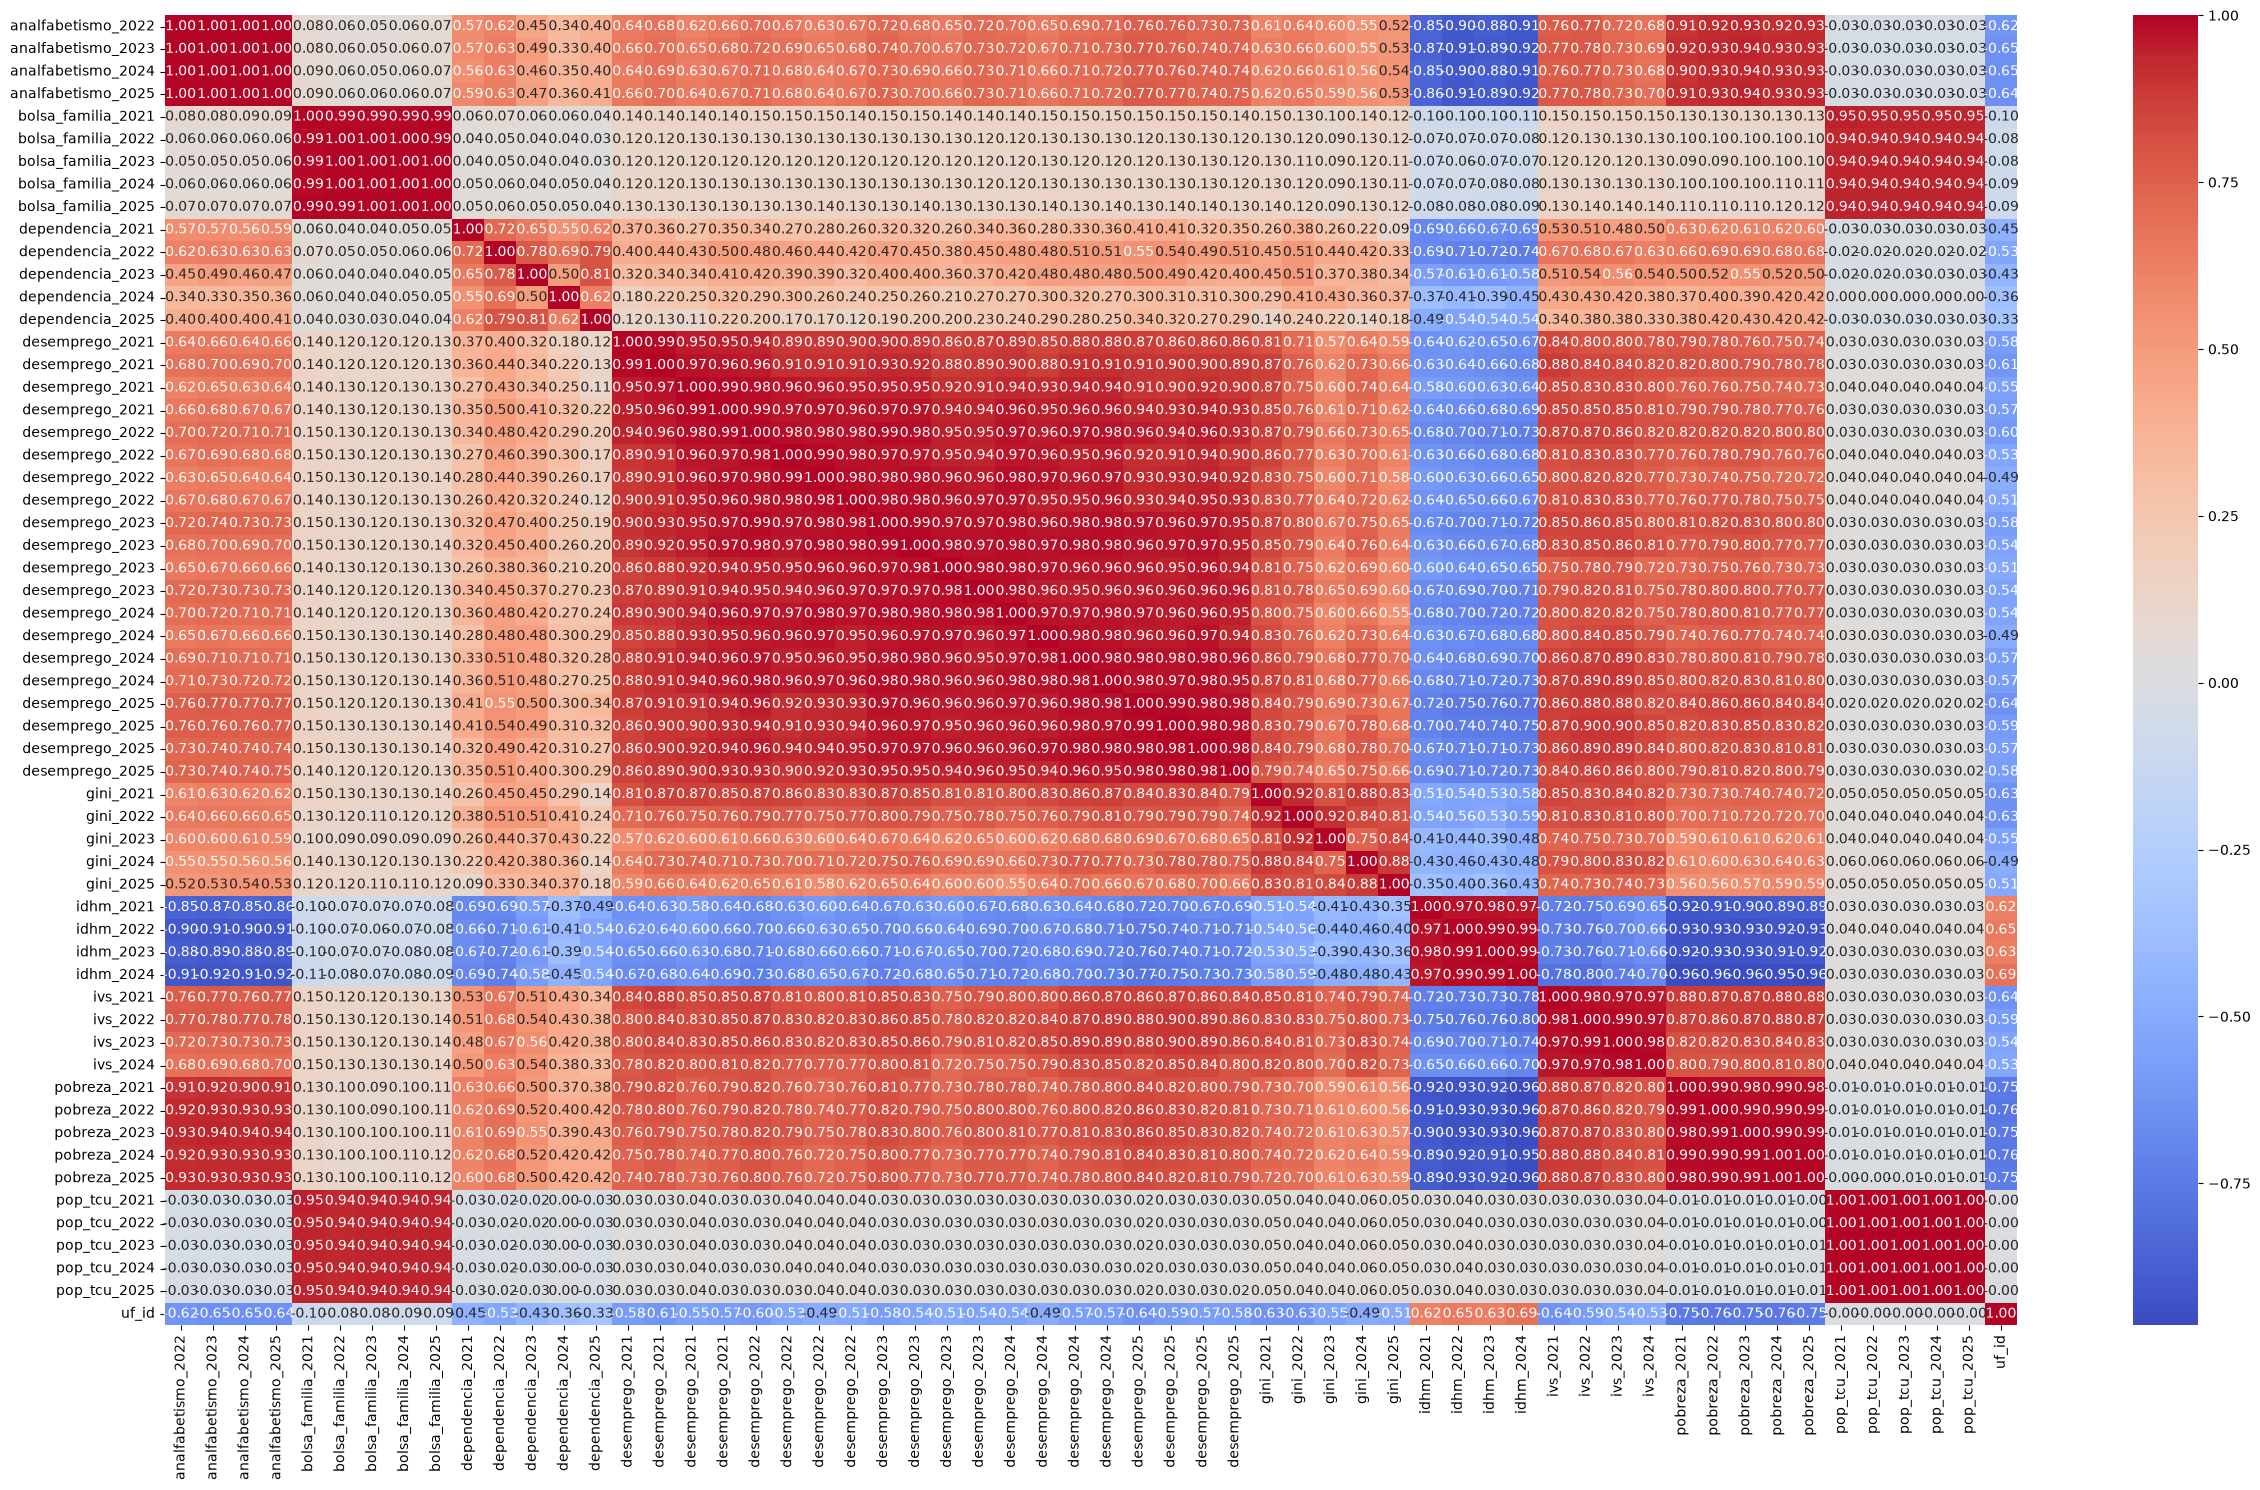

In [178]:
cols = base.select_dtypes(include=np.number).columns

cols = cols.difference(['Cód.', 'municipio_id'])

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(25,15))
sns.heatmap(base[cols].corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.tight_layout()
plt.show()


In [180]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant


In [183]:
base[cols].isna().sum()

analfabetismo_2022    0
analfabetismo_2023    0
analfabetismo_2024    0
analfabetismo_2025    0
bolsa_familia_2021    1
bolsa_familia_2022    1
bolsa_familia_2023    1
bolsa_familia_2024    1
bolsa_familia_2025    1
dependencia_2021      0
dependencia_2022      0
dependencia_2023      0
dependencia_2024      0
dependencia_2025      0
desemprego_2021       0
desemprego_2021       0
desemprego_2021       0
desemprego_2021       0
desemprego_2022       0
desemprego_2022       0
desemprego_2022       0
desemprego_2022       0
desemprego_2023       0
desemprego_2023       0
desemprego_2023       0
desemprego_2023       0
desemprego_2024       0
desemprego_2024       0
desemprego_2024       0
desemprego_2024       0
desemprego_2025       0
desemprego_2025       0
desemprego_2025       0
desemprego_2025       0
gini_2021             0
gini_2022             0
gini_2023             0
gini_2024             0
gini_2025             0
idhm_2021             0
idhm_2022             0
idhm_2023       

In [184]:
X = base[cols].dropna()

# Add a constant to the model (intercept)
X = add_constant(X)

# Calculate VIF for each feature
datacamp_vif_data = pd.DataFrame()
datacamp_vif_data['Feature'] = X.columns
datacamp_vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(datacamp_vif_data)

C:\Users\deinf.janaelson\AppData\Local\Temp\ipykernel_48392\1191046140.py:9: UserWarning: The design matrix is poorly conditioned (condition number=1.20e+17). VIF calculations may be numerically unstable.
  datacamp_vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
c:\Projetos\eda-disque100-completo\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Projetos\eda-disque100-completo\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Projetos\eda-disque100-completo\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are

               Feature           VIF
0                const  1.007255e+00
1   analfabetismo_2022  4.090863e+06
2   analfabetismo_2023  4.888264e+07
3   analfabetismo_2024  8.273144e+07
4   analfabetismo_2025  1.016757e+08
5   bolsa_familia_2021  1.191236e+02
6   bolsa_familia_2022  6.978728e+02
7   bolsa_familia_2023  1.960753e+03
8   bolsa_familia_2024  3.403272e+03
9   bolsa_familia_2025  1.499312e+03
10    dependencia_2021  1.258646e+08
11    dependencia_2022  4.004503e+06
12    dependencia_2023  1.219231e+06
13    dependencia_2024  1.586826e+08
14    dependencia_2025  1.949481e+06
15     desemprego_2021  6.458454e+07
16     desemprego_2021  7.900981e+06
17     desemprego_2021  1.841872e+07
18     desemprego_2021  2.505994e+06
19     desemprego_2022  4.811028e+06
20     desemprego_2022  3.699331e+06
21     desemprego_2022  1.029955e+07
22     desemprego_2022  1.042013e+06
23     desemprego_2023  1.971165e+07
24     desemprego_2023  1.279124e+06
25     desemprego_2023  2.946314e+04
2

c:\Projetos\eda-disque100-completo\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Projetos\eda-disque100-completo\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Projetos\eda-disque100-completo\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Projetos\eda-disque100-completo\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_n